# Hồi quy Softmax (Đa lớp - Multinomial Logistic Regression)

Hồi quy Softmax mở rộng khả năng của Logistic Regression từ bài toán phân loại 2 lớp lên $K$ lớp. Trọng số $w$ không còn là một vector mà trở thành một ma trận $W \in \mathbb{R}^{(D+1) \times K}$, trong đó mỗi cột đại diện cho bộ trọng số của một lớp.

**1. Hàm giả thuyết (Softmax):**
Mô hình tính toán điểm số (logits) cho từng lớp: $Z = \Phi W$.
Sau đó, dùng hàm Softmax để chuyển đổi các điểm số này thành phân bố xác suất:
$$\hat{Y}_{i,k} = P(y_i = k | x_i, W) = \frac{\exp(Z_{i,k})}{\sum_{j=1}^K \exp(Z_{i,j})}$$

**2. Hàm mất mát (Categorical Cross-Entropy):**
Đối chiếu xác suất dự đoán $\hat{Y}$ với ma trận nhãn One-Hot $Y$:
$$\mathcal{L}(W) = -\frac{1}{N} \sum_{i=1}^N \sum_{k=1}^K Y_{i,k} \log(\hat{Y}_{i,k})$$

**3. Gradient Descent:**
Đạo hàm của hàm mất mát theo ma trận trọng số $W$ có dạng tuyệt đẹp, giữ nguyên sự thanh lịch của các thuật toán tuyến tính trước đó:
$$\nabla_W \mathcal{L} = \Phi^T \frac{(\hat{Y} - Y)}{N}$$

In [5]:
import numpy as np
from utils.losses import CategoricalCrossEntropy
from utils.activations import softmax
from utils.preprocessing import OneHotEncoder

class SoftmaxRegressionGD:
    """Phân loại đa lớp (Multi-class) bằng Gradient Descent."""
    def __init__(self, learning_rate=0.1, epochs=1000, fit_intercept=True):
        self.lr = learning_rate
        self.epochs = epochs
        self.fit_intercept = fit_intercept
        self.weights = None # Sẽ là ma trận (D, K)
        self.intercept = None # Sẽ là vector (1, K)
        self.loss_history = []
        self.encoder = OneHotEncoder()
        self.cce = CategoricalCrossEntropy()

    def fit(self, X: np.ndarray, y: np.ndarray):
        X = np.asarray(X)
        N, D = X.shape
        
        # Chuyển đổi nhãn y thành ma trận One-Hot Y (N, K)
        Y_onehot = self.encoder.fit_transform(y)
        K = Y_onehot.shape[1]
        
        Phi = np.hstack([np.ones((N, 1)), X]) if self.fit_intercept else X
        
        # Khởi tạo ma trận trọng số ngẫu nhiên W có kích thước (D+1, K)
        np.random.seed(42)
        W = np.random.randn(Phi.shape[1], K) * 0.01

        for _ in range(self.epochs):
            # Forward pass: Phi @ W -> (N, K)
            Z = Phi @ W
            Y_pred = softmax(Z)
            
            # Ghi nhận Loss
            loss = self.cce.forward(Y_onehot, Y_pred)
            self.loss_history.append(loss)
            
            # Backward pass: Đạo hàm gộp của [Softmax + CCE] theo pre-activation Z
            grad_Z = (Y_pred - Y_onehot) / N
            grad_W = Phi.T @ grad_Z
            
            # Cập nhật trọng số
            W -= self.lr * grad_W

        if self.fit_intercept:
            self.intercept = W[0, :].reshape(1, -1)
            self.weights = W[1:, :]
        else:
            self.intercept = np.zeros((1, K))
            self.weights = W
            
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        Z = np.asarray(X) @ self.weights + self.intercept
        return softmax(Z)

    def predict(self, X: np.ndarray) -> np.ndarray:
        # Trả về nhãn có xác suất cao nhất (argmax theo trục cột)
        Y_pred = self.predict_proba(X)
        class_indices = np.argmax(Y_pred, axis=1)
        return self.encoder.classes_[class_indices]

Metric               | Scratch         | Sklearn        
-------------------------------------------------------
Accuracy Score       | 0.9875          | 0.9875         
Time (ms)            | 50.31           | 2.52           


f:\conda-path\envs\env_researcher\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


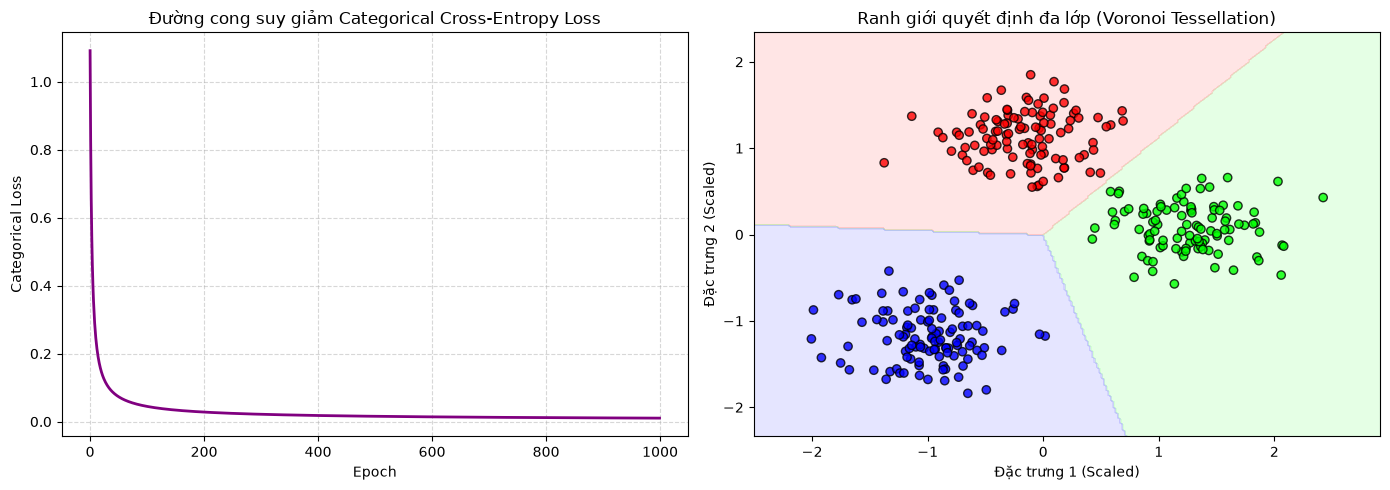

In [6]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_blobs
from utils.metrics import accuracy_score
from utils.preprocessing import StandardScaler, train_test_split

# 1. Sinh dữ liệu 3 lớp (Clusters)
X, y = make_blobs(n_samples=400, centers=3, n_features=2, random_state=42, cluster_std=2.0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Huấn luyện model Scratch
t0 = time.time()
model_scratch = SoftmaxRegressionGD(learning_rate=0.5, epochs=1000).fit(X_train_scaled, y_train)
t_scratch = (time.time() - t0) * 1000

# 4. Huấn luyện model Sklearn (Thiết lập multinomial)
t0 = time.time()
# model_sklearn = LogisticRegression(multi_class='multinomial', penalty=None, solver='lbfgs').fit(X_train_scaled, y_train) -> hư viện scikit-learn phiên bản mới nhất (từ 1.5 trở đi) đã loại bỏ hoàn toàn tham số multi_class
model_sklearn = LogisticRegression(penalty=None, solver='lbfgs').fit(X_train_scaled, y_train)
t_sklearn = (time.time() - t0) * 1000

# 5. Đánh giá
y_pred_scratch = model_scratch.predict(X_test_scaled)
y_pred_sklearn = model_sklearn.predict(X_test_scaled)

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn':<15}")
print("-" * 55)
print(f"{'Accuracy Score':<20} | {accuracy_score(y_test, y_pred_scratch):<15.4f} | {accuracy_score(y_test, y_pred_sklearn):<15.4f}")
print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")

# 6. Trực quan hóa ranh giới phân loại 3 màu
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: Loss Curve
ax1.plot(model_scratch.loss_history, color='purple', lw=2)
ax1.set_title("Đường cong suy giảm Categorical Cross-Entropy Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Categorical Loss")
ax1.grid(True, linestyle='--', alpha=0.5)

# Đồ thị 2: Decision Boundary (Đa lớp)
x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = model_scratch.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

from matplotlib.colors import ListedColormap
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

ax2.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
ax2.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train, cmap=cmap_bold, edgecolors='k', alpha=0.8)
ax2.set_title("Ranh giới quyết định đa lớp (Voronoi Tessellation)")
ax2.set_xlabel("Đặc trưng 1 (Scaled)")
ax2.set_ylabel("Đặc trưng 2 (Scaled)")

plt.tight_layout()
plt.show()